<a href="https://colab.research.google.com/github/godfreyM04/PS-Agents/blob/main/UCS_Trailer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
### 1. Problem Formulation
# In this notebook, we implement **Uniform Cost Search (UCS)** to find the optimal route for a self-driving trailer traversing Kenya's highway network from **Nairobi** to **Kisumu**..

# * **Initial State: Nairobi
# * **Goal State: Kisumu
# * **State Space: Cities and major highway towns across Nairobi, Central Highlands, Rift Valley, and Lake Victoria Basin.
# * **Actions: Directed highway segments connecting adjacent towns.
# * **Step Cost: Distance in kilometers (km) between connected towns.
# * **Path Cost: Cumulative highway distance from Nairobi to node.

In [1]:
import heapq
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

# Directed Graph representing Kenya's Highway Network (Nairobi -> Central -> Rift Valley -> Lake Basin)
# Format: 'Town': [('Neighbor1', distance_km), ('Neighbor2', distance_km), ...]
highway_graph = {
    'Nairobi': [('Limuru', 37), ('Thika', 45)],
    'Limuru': [('Naivasha', 55), ('Narok', 108)],
    'Thika': [('Nyeri', 108)],
    'Nyeri': [('Nyahururu', 65)],
    'Nyahururu': [('Nakuru', 67)],
    'Naivasha': [('Gilgil', 28)],
    'Gilgil': [('Nakuru', 40), ('Nyahururu', 58)],
    'Narok': [('Bomet', 115)],
    'Bomet': [('Kericho', 83), ('Kisii', 72)],
    'Kisii': [('Ahero', 92)],
    'Nakuru': [('Mau Summit', 55)],
    'Mau Summit': [('Kericho', 52), ('Eldoret', 105)],
    'Kericho': [('Ahero', 61)],
    'Ahero': [('Kisumu', 24)],
    'Eldoret': [('Kapsabet', 44), ('Webuye', 63)],
    'Kapsabet': [('Kisumu', 68)],
    'Webuye': [('Kakamega', 42)],
    'Kakamega': [('Kisumu', 50)],
    'Kisumu': []  # Goal Node
}

print(f"Loaded Highway Graph with {len(highway_graph)} nodes.")

Loaded Highway Graph with 19 nodes.


In [2]:
def uniform_cost_search_trace(graph, start_node, goal_node):
    """
    Executes Uniform Cost Search (UCS) from start_node to goal_node,
    logging every expansion step, frontier state, and explored set as done in class.
    """
    # Priority Queue stores tuples: (cumulative_cost, current_node, path_list)
    frontier = [(0, start_node, [start_node])]

    # Dictionary tracking the lowest cost found so far to reach each node on the frontier
    best_cost_to_node = {start_node: 0}

    # Explored set (Closed List) to avoid re-expanding nodes whose optimal cost is finalized
    explored = []

    # Log table for clean classroom-style trace presentation
    trace_log = []
    step = 1

    print("=" * 95)
    print(f"{'UNIFORM COST SEARCH STEP-BY-STEP TRAVERSAL TRACE':^95}")
    print("=" * 95)

    while frontier:
        # Sort frontier snapshot for display before popping
        frontier_snapshot = sorted(frontier, key=lambda x: x[0])
        frontier_str = ", ".join([f"{node}({cost})" for cost, node, _ in frontier_snapshot])

        # Pop the node with the lowest cumulative path cost g(n)
        current_cost, current_node, current_path = heapq.heappop(frontier)

        # Skip stale priority queue entries if a strictly cheaper path was already expanded
        if current_node in explored:
            continue

        # Record state before expanding neighbors
        explored_str = ", ".join(explored) if explored else "{}"
        print(f"\n[Step {step:02d}] Expanding Node : {current_node} (g = {current_cost} km)")
        print(f"          Current Path   : {' -> '.join(current_path)}")
        print(f"          Frontier (In)  : [{frontier_str}]")
        print(f"          Explored Set   : {explored_str}")

        trace_log.append({
            "Step": step,
            "Expanded Node": f"{current_node} ({current_cost} km)",
            "Path to Node": " -> ".join(current_path),
            "Frontier (Before Expansion)": frontier_str,
            "Explored Set": explored_str
        })

        # Goal Test applied upon expansion
        if current_node == goal_node:
            print("\n" + "=" * 95)
            print(f"GOAL REACHED AT STEP {step}! Optimal path to '{goal_node}' verified.")
            print("=" * 95)
            return current_path, current_cost, pd.DataFrame(trace_log)

        # Mark node as explored
        explored.append(current_node)

        # Expand neighbors
        generated_children = []
        for neighbor, step_cost in graph.get(current_node, []):
            new_cost = current_cost + step_cost
            if neighbor not in explored:
                if neighbor not in best_cost_to_node or new_cost < best_cost_to_node[neighbor]:
                    best_cost_to_node[neighbor] = new_cost
                    new_path = current_path + [neighbor]
                    heapq.heappush(frontier, (new_cost, neighbor, new_path))
                    generated_children.append(f"{neighbor}(g={new_cost})")

        if generated_children:
            print(f"          Generated/Upd  : {', '.join(generated_children)}")
        else:
            print(f"          Generated/Upd  : None (All neighbors already explored or cheaper)")

        step += 1

    return None, float("inf"), pd.DataFrame(trace_log)

# Execute the search from Nairobi to Kisumu
optimal_path, optimal_cost, trace_df = uniform_cost_search_trace(highway_graph, 'Nairobi', 'Kisumu')

                       UNIFORM COST SEARCH STEP-BY-STEP TRAVERSAL TRACE                        

[Step 01] Expanding Node : Nairobi (g = 0 km)
          Current Path   : Nairobi
          Frontier (In)  : [Nairobi(0)]
          Explored Set   : {}
          Generated/Upd  : Limuru(g=37), Thika(g=45)

[Step 02] Expanding Node : Limuru (g = 37 km)
          Current Path   : Nairobi -> Limuru
          Frontier (In)  : [Limuru(37), Thika(45)]
          Explored Set   : Nairobi
          Generated/Upd  : Naivasha(g=92), Narok(g=145)

[Step 03] Expanding Node : Thika (g = 45 km)
          Current Path   : Nairobi -> Thika
          Frontier (In)  : [Thika(45), Naivasha(92), Narok(145)]
          Explored Set   : Nairobi, Limuru
          Generated/Upd  : Nyeri(g=153)

[Step 04] Expanding Node : Naivasha (g = 92 km)
          Current Path   : Nairobi -> Limuru -> Naivasha
          Frontier (In)  : [Naivasha(92), Narok(145), Nyeri(153)]
          Explored Set   : Nairobi, Limuru, Thika
     

In [3]:
# Display the structured search table as done in class
print("\n### Classroom Search Trace Table ###")
display(trace_df.style.set_properties(**{'text-align': 'left'}).hide(axis='index'))

# Present final optimal route and segment breakdown
print("\n" + "#" * 70)
print("FINAL OPTIMAL PATH & COST SUMMARY (NAIROBI -> KISUMU)")
print("#" * 70)
print(f"Optimal RouteSequence : {' -> '.join(optimal_path)}")
print(f"Total Optimal Cost    : {optimal_cost} km\n")

print("Segment-by-Segment Breakdown:")
cumulative = 0
for i in range(len(optimal_path) - 1):
    u, v = optimal_path[i], optimal_path[i + 1]
    edge_cost = next(cost for nbr, cost in highway_graph[u] if nbr == v)
    cumulative += edge_cost
    print(f"  {i+1}. {u:<12} -> {v:<12} : +{edge_cost:>3} km  (Cumulative: {cumulative:>3} km)")


### Classroom Search Trace Table ###


Step,Expanded Node,Path to Node,Frontier (Before Expansion),Explored Set
1,Nairobi (0 km),Nairobi,Nairobi(0),{}
2,Limuru (37 km),Nairobi -> Limuru,"Limuru(37), Thika(45)",Nairobi
3,Thika (45 km),Nairobi -> Thika,"Thika(45), Naivasha(92), Narok(145)","Nairobi, Limuru"
4,Naivasha (92 km),Nairobi -> Limuru -> Naivasha,"Naivasha(92), Narok(145), Nyeri(153)","Nairobi, Limuru, Thika"
5,Gilgil (120 km),Nairobi -> Limuru -> Naivasha -> Gilgil,"Gilgil(120), Narok(145), Nyeri(153)","Nairobi, Limuru, Thika, Naivasha"
6,Narok (145 km),Nairobi -> Limuru -> Narok,"Narok(145), Nyeri(153), Nakuru(160), Nyahururu(178)","Nairobi, Limuru, Thika, Naivasha, Gilgil"
7,Nyeri (153 km),Nairobi -> Thika -> Nyeri,"Nyeri(153), Nakuru(160), Nyahururu(178), Bomet(260)","Nairobi, Limuru, Thika, Naivasha, Gilgil, Narok"
8,Nakuru (160 km),Nairobi -> Limuru -> Naivasha -> Gilgil -> Nakuru,"Nakuru(160), Nyahururu(178), Bomet(260)","Nairobi, Limuru, Thika, Naivasha, Gilgil, Narok, Nyeri"
9,Nyahururu (178 km),Nairobi -> Limuru -> Naivasha -> Gilgil -> Nyahururu,"Nyahururu(178), Mau Summit(215), Bomet(260)","Nairobi, Limuru, Thika, Naivasha, Gilgil, Narok, Nyeri, Nakuru"
10,Mau Summit (215 km),Nairobi -> Limuru -> Naivasha -> Gilgil -> Nakuru -> Mau Summit,"Mau Summit(215), Bomet(260)","Nairobi, Limuru, Thika, Naivasha, Gilgil, Narok, Nyeri, Nakuru, Nyahururu"



######################################################################
FINAL OPTIMAL PATH & COST SUMMARY (NAIROBI -> KISUMU)
######################################################################
Optimal RouteSequence : Nairobi -> Limuru -> Naivasha -> Gilgil -> Nakuru -> Mau Summit -> Kericho -> Ahero -> Kisumu
Total Optimal Cost    : 352 km

Segment-by-Segment Breakdown:
  1. Nairobi      -> Limuru       : + 37 km  (Cumulative:  37 km)
  2. Limuru       -> Naivasha     : + 55 km  (Cumulative:  92 km)
  3. Naivasha     -> Gilgil       : + 28 km  (Cumulative: 120 km)
  4. Gilgil       -> Nakuru       : + 40 km  (Cumulative: 160 km)
  5. Nakuru       -> Mau Summit   : + 55 km  (Cumulative: 215 km)
  6. Mau Summit   -> Kericho      : + 52 km  (Cumulative: 267 km)
  7. Kericho      -> Ahero        : + 61 km  (Cumulative: 328 km)
  8. Ahero        -> Kisumu       : + 24 km  (Cumulative: 352 km)


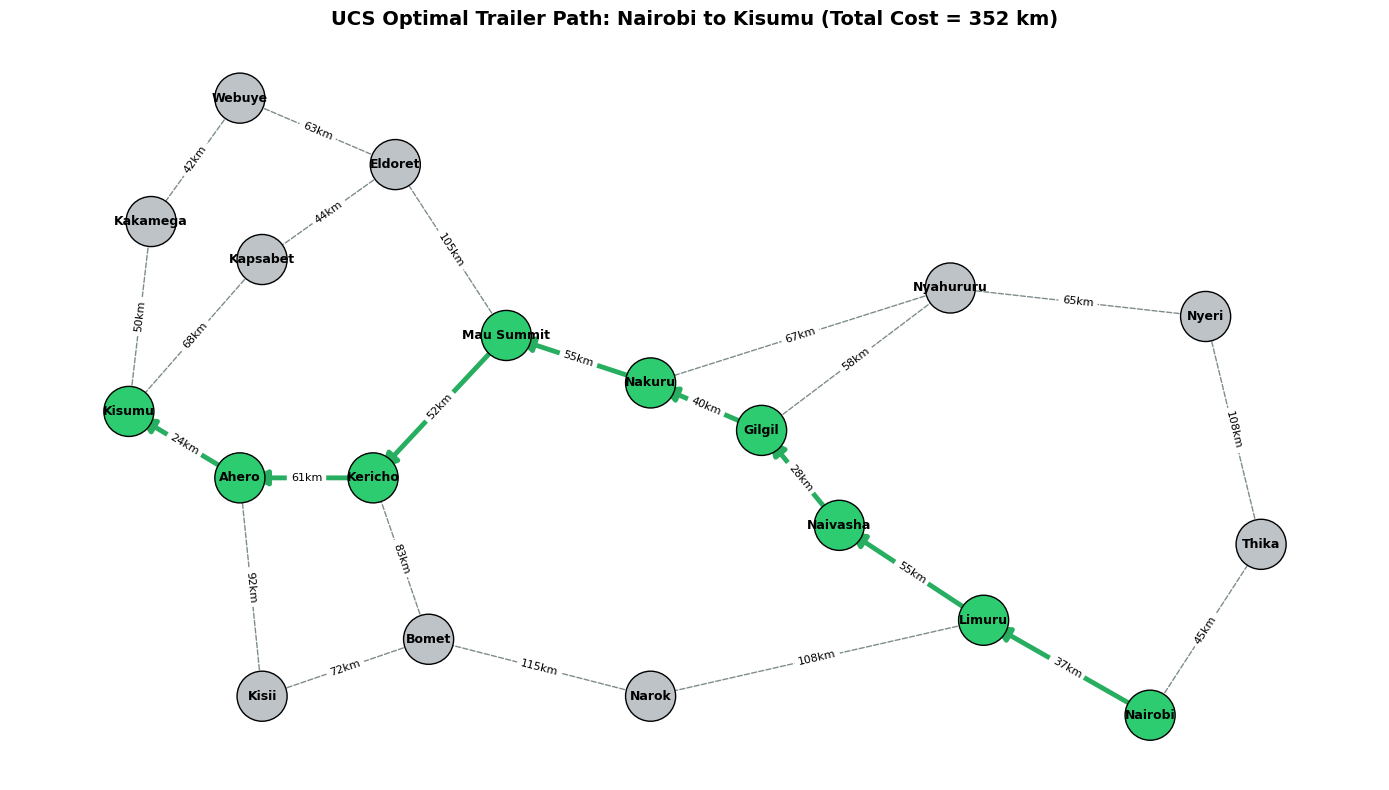

In [4]:
# Visualize the directed graph and highlight the optimal UCS path in green
G = nx.DiGraph()
for src, neighbors in highway_graph.items():
    for dst, weight in neighbors:
        G.add_edge(src, dst, weight=weight)

# Approximate geographical layout coordinates (Longitude, Latitude style) for clarity
pos = {
    'Nairobi': (10, 1),
    'Limuru': (8.5, 2),
    'Thika': (11, 2.8),
    'Nyeri': (10.5, 5.2),
    'Nyahururu': (8.2, 5.5),
    'Naivasha': (7.2, 3),
    'Gilgil': (6.5, 4),
    'Narok': (5.5, 1.2),
    'Bomet': (3.5, 1.8),
    'Kisii': (2.0, 1.2),
    'Nakuru': (5.5, 4.5),
    'Mau Summit': (4.2, 5.0),
    'Kericho': (3.0, 3.5),
    'Ahero': (1.8, 3.5),
    'Eldoret': (3.2, 6.8),
    'Kapsabet': (2.0, 5.8),
    'Webuye': (1.8, 7.5),
    'Kakamega': (1.0, 6.2),
    'Kisumu': (0.8, 4.2)
}

plt.figure(figsize=(14, 8))
optimal_edges = list(zip(optimal_path[:-1], optimal_path[1:]))

# Node colors
node_colors = ['#2ecc71' if node in optimal_path else '#bdc3c7' for node in G.nodes()]
nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=1300, edgecolors='black')
nx.draw_networkx_labels(G, pos, font_size=9, font_weight='bold')

# Non-optimal edges vs Optimal path edges
regular_edges = [e for e in G.edges() if e not in optimal_edges]
nx.draw_networkx_edges(G, pos, edgelist=regular_edges, edge_color='#7f8c8d', arrows=True, arrowsize=15, style='dashed')
nx.draw_networkx_edges(G, pos, edgelist=optimal_edges, edge_color='#27ae60', width=3.5, arrows=True, arrowsize=22)

# Edge weight labels
edge_labels = {(u, v): f"{d['weight']}km" for u, v, d in G.edges(data=True)}
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=8)

plt.title(f"UCS Optimal Trailer Path: Nairobi to Kisumu (Total Cost = {optimal_cost} km)", fontsize=14, fontweight='bold')
plt.axis('off')
plt.tight_layout()
plt.show()

In [ ]:
# ---
# ### Evidence of Groupwork

# #### Group Members
# | # | Student Admission No. | Full Name | Role / Contribution |
# | :- | :--- | :--- | :--- | :--- |
# | 1 | 191244 | Godffrey Mark Onyango | Graph Modeling & UCS Python Implementation |
# | 2 | 191917 | Mutitu Alex Kigo | (Insert role) |
# | 3 | 191959 | Okumu Eli Ndeda | (Insert role) |


# #### Team Meeting Photo
### Will be inserted here
